In [ ]:
!pip install -q yfinance lxml pyarrow

import io, datetime as dt,json
import numpy as np, pandas as pd, requests, yfinance as yf
import scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA


In [ ]:
START, END = "2021-01-01", "2025-01-01"  # END is exclusive
BENCHMARK = "^GSPC"
SEED = 42
MIN_SESSIONS = 80  # 20-session baseline + latest 60-session RFM window
MIN_WEEKS = 52     # minimum aligned weekly observations; explain this chosen quality threshold
LAST_FULL_WEEK = pd.Timestamp("2024-12-27")  # final complete Friday-ending week in the requested period

for name, mod in [("pandas", pd), ("numpy", np), ("yfinance", yf),
                  ("scikit-learn", sklearn), ("scipy", scipy),
                  ("matplotlib", matplotlib)]:
    print(name, mod.__version__)
print("Data period:", START, "to", END, "(end date exclusive)")
print("Run date:", dt.date.today().isoformat())


pandas 2.2.3
numpy 2.4.6
yfinance 0.2.66
scikit-learn 1.6.1
scipy 1.16.3
matplotlib 3.10.0
Data period: 2021-01-01 to 2025-01-01 (end date exclusive)
Run date: 2026-11-23


In [ ]:
url = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"
html = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}).text
constituents = pd.read_html(io.StringIO(html))[0]
RETRIEVAL_DATE = dt.date.today().isoformat()
constituents["Ticker"] = constituents["Symbol"].str.replace(".", "-", regex=False)  # BRK.B -> BRK-B
constituents["Retrieved"] = RETRIEVAL_DATE
constituents.to_csv("sp500_constituents.csv", index=False)
tickers = constituents["Ticker"].tolist()
print("Retrieved on", RETRIEVAL_DATE, "|", len(tickers), "tickers")



Retrieved on 2026-11-23 | 503 tickers


In [ ]:
exclusions = []
batches, bs = [], 50
for i in range(0, len(tickers), bs):
    d = yf.download(tickers[i:i+bs], start=START, end=END, auto_adjust=False,
                    progress=False, threads=True)
    batches.append(d); print("batch", i // bs + 1, d.shape)
prices = pd.concat(batches, axis=1)
bench  = yf.download(BENCHMARK, start=START, end=END, auto_adjust=False, progress=False)

try:
    prices.to_parquet("sp500_raw_prices.parquet"); bench.to_parquet("gspc_raw.parquet")
except Exception as e:
    print("parquet failed, using pickle:", e)
    prices.to_pickle("sp500_raw_prices.pkl"); bench.to_pickle("gspc_raw.pkl")

print(prices.columns.names, prices["Adj Close"].index.min().date(), prices["Adj Close"].index.max().date())
# Extract daily stock data
adj = prices["Adj Close"].copy()
close = prices["Close"].copy()
vol = prices["Volume"].copy()

# Extract benchmark data
b_adj = bench["Adj Close"].copy()

if isinstance(b_adj, pd.DataFrame):
    b_adj = b_adj.iloc[:, 0]

print("Adjusted Close:", adj.shape)
print("Close:", close.shape)
print("Volume:", vol.shape)
print("Benchmark:", b_adj.shape)

display(adj.head())

batch 1 (1005, 300)
batch 2 (1005, 300)
batch 3 (1005, 300)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['FDXF']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


batch 4 (1005, 300)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['HONA']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


batch 5 (1005, 300)
batch 6 (1005, 300)
batch 7 (1005, 300)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


... (2 outputs left out)

batch 9 (1005, 300)


ERROR:yfinance:
1 Failed download:
ERROR:yfinance:['VYLR']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


batch 10 (1005, 300)
batch 11 (1005, 18)
['Price', 'Ticker'] 2021-01-04 2024-12-31
Adjusted Close: (1005, 503)
Close: (1005, 503)
Volume: (1005, 503)
Benchmark: (1005,)


Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,...,WST,WTW,WY,WYNN,XEL,XYL,YUM,ZBH,ZBRA,ZTS
Date,,,,,,,,,,,,,,,,,,,,,
2021-01-04,114.009125,125.537102,84.219154,139.149994,97.269699,33.186359,232.029327,485.339996,132.622665,42.189484,...,281.226227,188.764465,26.124496,102.852097,54.757385,93.015900,95.016190,141.603363,378.130005,152.952026
2021-01-05,114.941269,127.089249,85.089989,148.300003,98.473198,33.319485,233.350266,485.690002,134.993118,43.010090,...,286.593292,187.189133,26.371323,106.017532,54.223652,92.903946,95.025177,144.053375,380.570007,154.017853
2021-01-06,118.093239,122.811211,84.354942,142.770004,98.268158,34.783871,235.901642,466.309998,135.601715,44.752827,...,289.665894,188.764465,26.506691,106.652527,55.424545,96.822739,95.545967,148.158417,394.820007,156.280487
2021-01-07,121.235596,127.001915,85.257797,151.270004,99.222054,34.460564,238.127289,477.739990,141.332748,44.355213,...,299.435059,190.200867,26.761486,105.594170,54.340405,101.217407,94.818657,147.280060,409.100006,156.140289
2021-01-08,122.100471,128.098099,85.705223,149.770004,99.498421,34.650742,238.995850,485.100006,142.359070,44.473652,...,302.852234,188.708908,26.578350,104.901436,54.840767,100.191048,96.210388,146.956482,405.470001,157.178101


In [ ]:
# Separate missingness reporting from hard data-quality exclusions.
# Missing prices are NOT forward-filled. Shares are excluded only for hard errors
# or insufficient usable history; remaining missing observations stay missing.

# Ensure dates are unique and ordered. Keep the last record if Yahoo returns duplicate dates.
duplicate_dates = int(adj.index.duplicated().sum())
print("Duplicate dates before cleaning:", duplicate_dates)
if duplicate_dates:
    adj = adj.loc[~adj.index.duplicated(keep="last")].sort_index()
    close = close.loc[~close.index.duplicated(keep="last")].sort_index()
    vol = vol.loc[~vol.index.duplicated(keep="last")].sort_index()

# Align all three price/volume matrices to the same date index and ticker columns.
common_tickers = adj.columns.intersection(close.columns).intersection(vol.columns)
adj, close, vol = adj[common_tickers], close[common_tickers], vol[common_tickers]
close = close.reindex(index=adj.index, columns=adj.columns)
vol = vol.reindex(index=adj.index, columns=adj.columns)

missing_report = pd.DataFrame({
    "AdjClose_missing": adj.isna().sum(),
    "Close_missing": close.isna().sum(),
    "Volume_missing": vol.isna().sum(),
    "AdjClose_nonpositive": (adj <= 0).sum(),
    "Close_nonpositive": (close <= 0).sum(),
    "Negative_volume": (vol < 0).sum(),
    "Zero_volume_days": (vol == 0).sum()
})
print("Missingness and quality summary (first rows):")
display(missing_report.head(10))
missing_report.to_csv("daily_data_quality_report.csv")

for t in adj.columns[adj.isna().all()]:
    exclusions.append((t, "No adjusted-price data returned by Yahoo", "1.1"))

hard_bad_price = ((adj <= 0) | (close <= 0)).any()
hard_bad_volume = (vol < 0).any()
for t in hard_bad_price[hard_bad_price].index:
    exclusions.append((t, "At least one non-positive adjusted or close price", "1.2"))
for t in hard_bad_volume[hard_bad_volume].index:
    exclusions.append((t, "At least one negative volume observation", "1.2"))

# Remove hard-error tickers, but do not silently fill or discard isolated missing observations.
drop_hard = set(hard_bad_price[hard_bad_price].index) | set(hard_bad_volume[hard_bad_volume].index)
keep = [t for t in adj.columns if t not in drop_hard and not adj[t].isna().all()]
adj, close, vol = adj[keep], close[keep], vol[keep]

# Coverage report: shorter histories are identified and later screened by usable observations.
coverage = pd.DataFrame({
    "AdjClose_sessions": adj.notna().sum(),
    "Close_sessions": close.notna().sum(),
    "Volume_sessions": vol.notna().sum(),
    "First_valid_date": [adj[t].first_valid_index() for t in adj.columns],
    "Last_valid_date": [adj[t].last_valid_index() for t in adj.columns]
})
print("Shares with fewer than", MIN_SESSIONS, "usable adjusted-close sessions:",
      int((coverage["AdjClose_sessions"] < MIN_SESSIONS).sum()))
print("Shares with any zero-volume days:", int((vol == 0).any().sum()))
print("Hard-error exclusions:", len(drop_hard))


Duplicate dates before cleaning: 0
Missingness and quality summary (first rows):


,AdjClose_missing,Close_missing,Volume_missing,AdjClose_nonpositive,Close_nonpositive,Negative_volume,Zero_volume_days
Ticker,,,,,,,
A,0,0,0,0,0,0,0
AAPL,0,0,0,0,0,0,0
ABBV,0,0,0,0,0,0,0
ABNB,0,0,0,0,0,0,0
ABT,0,0,0,0,0,0,0
ACGL,0,0,0,0,0,0,0
ACN,0,0,0,0,0,0,0
ADBE,0,0,0,0,0,0,0
ADI,0,0,0,0,0,0,0


Shares with fewer than 80 usable adjusted-close sessions: 0
Shares with any zero-volume days: 2
Hard-error exclusions: 0


In [ ]:
# Download split histories. Handle both timezone-aware and timezone-naive indices.
splits_dict = {}
print("Downloading split histories for candidate tickers...")
for t in keep:
    try:
        split_series = yf.Ticker(t).splits
        if split_series is None or split_series.empty:
            continue
        split_series = split_series.copy()
        split_series.index = pd.to_datetime(split_series.index)
        if getattr(split_series.index, "tz", None) is not None:
            split_series.index = split_series.index.tz_localize(None)
        split_series.index = split_series.index.normalize()
        split_series = split_series[(split_series.index >= START) & (split_series.index < END)]
        if not split_series.empty:
            splits_dict[t] = split_series
    except Exception as exc:
        print("Could not retrieve split history for", t, ":", exc)

spl = pd.DataFrame(0.0, index=adj.index, columns=keep)
for t, series in splits_dict.items():
    for split_date, ratio in series.items():
        # Match the corporate-action date to the nearest available trading date.
        pos = spl.index.get_indexer([split_date], method="nearest")[0]
        if pos >= 0:
            spl.iloc[pos, spl.columns.get_loc(t)] = float(ratio)

print("Tickers with split events in the study period:", len(splits_dict))


Tickers with split events in the study period: 53


In [ ]:
# Corporate-action diagnostics. These are investigation flags, not automatic proof of an error.
daily_close_return = close.pct_change(fill_method=None)
adjustment_factor = adj / close
adjustment_factor_change = adjustment_factor.pct_change(fill_method=None)

large_price_moves = daily_close_return.abs() > 0.40
large_factor_moves = adjustment_factor_change.abs() > 0.05
print("Daily Close moves greater than 40% by ticker:")
print(large_price_moves.sum().loc[lambda x: x > 0].sort_values(ascending=False).head(30))
print("\nAdjusted-Close/Close factor changes greater than 5% by ticker:")
print(large_factor_moves.sum().loc[lambda x: x > 0].sort_values(ascending=False).head(30))

split_audit_rows = []
for t in spl.columns[(spl > 0).any()]:
    for d in spl.index[spl[t] > 0]:
        i = spl.index.get_loc(d)
        before = vol[t].iloc[max(0, i-20):i].dropna()
        after = vol[t].iloc[i+1:i+21].dropna()
        split_audit_rows.append({
            "Ticker": t, "SplitTradingDate": d,
            "SplitRatio": spl.loc[d, t],
            "CloseReturnOnDate": daily_close_return.loc[d, t],
            "MeanVolumeAfter_over_Before": (
                after.mean() / before.mean()
                if len(before) and len(after) and before.mean() != 0 else np.nan
            ),
            "AdjCloseCloseFactorChange": adjustment_factor_change.loc[d, t]
        })

split_audit = pd.DataFrame(split_audit_rows)
display(split_audit.head(30))
split_audit.to_csv("corporate_action_audit.csv", index=False)

# Save date-level flags for manual review.
flag_rows = []
for t in keep:
    for d in daily_close_return.index[large_price_moves[t] | large_factor_moves[t]]:
        flag_rows.append({
            "Ticker": t, "Date": d,
            "CloseDailyReturn": daily_close_return.loc[d, t],
            "AdjustmentFactorChange": adjustment_factor_change.loc[d, t],
            "SplitRecorded": bool(spl.loc[d, t] > 0)
        })
corporate_flags = pd.DataFrame(flag_rows)
corporate_flags.to_csv("corporate_action_flags.csv", index=False)

print("Corporate-action flags are retained for investigation. Do not assume every large move is a split.")
print("For this coursework, weekly return/beta use Adj Close; RFM Monetary uses Close × Volume as specified.")
print("The split audit helps identify possible effects on Close and Volume; explain any material unresolved cases.")


Daily Close moves greater than 40% by ticker:
Ticker
CVNA    5
APP     1
BE      1
DXCM    1
GL      1
HOOD    1
RDDT    1
dtype: int64

Adjusted-Close/Close factor changes greater than 5% by ticker:
Ticker
ACGL    1
F       1
LYB     1
TDG     1
dtype: int64


,Ticker,SplitTradingDate,SplitRatio,CloseReturnOnDate,MeanVolumeAfter_over_Before,AdjCloseCloseFactorChange
0,AMZN,2022-06-06,20.000,0.019943,0.724953,0.000000e+00
1,ANET,2021-11-18,4.000,0.003558,0.865034,0.000000e+00
2,ANET,2024-12-04,4.000,0.017517,0.582937,0.000000e+00
3,APH,2021-03-05,2.000,0.025316,0.889739,1.654833e-07
4,APH,2024-06-12,2.000,0.021945,0.893064,-1.801198e-07
5,GOOG,2022-07-18,20.000,-0.025335,0.766609,2.721002e-08
6,GOOGL,2022-07-18,20.000,-0.024580,0.796239,3.314082e-08
7,MMM,2024-04-01,1.196,0.060129,0.507992,1.213753e-07
8,T,2022-04-11,1.324,0.076641,1.205759,1.572246e-08
9,AVGO,2024-07-15,10.000,0.007956,0.531491,1.829606e-07


Corporate-action flags are retained for investigation. Do not assume every large move is a split.
For this coursework, weekly return/beta use Adj Close; RFM Monetary uses Close × Volume as specified.
The split audit helps identify possible effects on Close and Volume; explain any material unresolved cases.


In [ ]:
# Check zero-volume days separately for each share

for t in vol.columns:
    s = vol[t].dropna()

    if (s == 0).any():
        zero_dates = s.index[s == 0]
        last80 = s.tail(80)

        print(
            t,
            "Zero-volume days:", len(zero_dates),
            "| First:", zero_dates.min().date(),
            "| Last:", zero_dates.max().date(),
            "| Zero-volume days in final 80 sessions:",
            int((last80 == 0).sum())
        )

FERG Zero-volume days: 27 | First: 2021-01-07 | Last: 2021-03-05 | Zero-volume days in final 80 sessions: 0
SW Zero-volume days: 424 | First: 2021-01-05 | Last: 2024-07-05 | Zero-volume days in final 80 sessions: 0


In [ ]:
if "exclusions" not in globals():
    exclusions = []

# Friday-ending weekly prices; no forward filling.
w_adj = adj.resample("W-FRI").last().loc[:LAST_FULL_WEEK]
w_bm = b_adj.resample("W-FRI").last().loc[:LAST_FULL_WEEK]
print("First weekly label:", w_adj.index[0].date(), "| last complete weekly label:", w_adj.index[-1].date())

# Calculate weekly returns
r_s = w_adj.pct_change(fill_method=None)
r_m = w_bm.pct_change(fill_method=None)

# Remove the first incomplete calendar week
r_s = r_s.iloc[1:]
r_m = r_m.iloc[1:]

rows = []
weekly_exclusions = []
for t in r_s.columns:
    pair = pd.concat([r_s[t].rename("Share"), r_m.rename("Benchmark")], axis=1).dropna()
    if len(pair) < MIN_WEEKS:
        weekly_exclusions.append((t, f"Only {len(pair)} aligned weekly returns (<{MIN_WEEKS})", "1.3"))
        continue
    benchmark_variance = pair["Benchmark"].var()
    if pd.isna(benchmark_variance) or benchmark_variance == 0:
        weekly_exclusions.append((t, "Benchmark weekly return variance is zero or undefined", "1.3"))
        continue
    rows.append({
        "Ticker": t,
        "MeanWeeklyReturn": pair["Share"].mean(),
        "Beta": pair["Share"].cov(pair["Benchmark"]) / benchmark_variance,
        "AlignedWeeks": len(pair)
    })
exclusions.extend(weekly_exclusions)
wk = pd.DataFrame(rows).set_index("Ticker")
print("Weekly feature table:", wk.shape)
display(wk.describe())

First weekly label: 2021-01-08 | last complete weekly label: 2024-12-27
Weekly feature table: (495, 3)


,MeanWeeklyReturn,Beta,AlignedWeeks
count,495.000000,495.000000,495.000000
mean,0.002925,0.982181,206.272727
std,0.002727,0.420918,8.364444
min,-0.004468,0.055453,64.000000
25%,0.001221,0.671765,207.000000
50%,0.002681,0.953176,207.000000
75%,0.004295,1.180579,207.000000
max,0.017772,3.778560,207.000000


In [ ]:
# Independent weekly return and beta check

t = "AAPL"

if t in wk.index:

    pair = pd.concat(
        [r_s[t], r_m],
        axis=1
    ).dropna()

    pair.columns = ["Share", "Benchmark"]

    print("Beta (covariance / variance):", wk.loc[t, "Beta"])

    print(
        "Beta (regression slope):",
        np.polyfit(pair["Benchmark"], pair["Share"], 1)[0]
    )

    w = w_adj[t]

    print(
        "Manual last weekly return:",
        w.iloc[-1] / w.iloc[-2] - 1
    )

    print("Table last weekly return:", r_s[t].iloc[-1])
    print("Aligned weekly observations:", len(pair))

else:

    print("AAPL is not included. Select another ticker from wk.index.")

Beta (covariance / variance): 1.1748363006504663
Beta (regression slope): 1.1748363006504667
Manual last weekly return: 0.00432219614198992
Table last weekly return: 0.00432219614198992
Aligned weekly observations: 207


In [ ]:
# Observation date: final date in the study period available for the benchmark and
# all candidate shares that passed the hard-error and weekly-history checks.
candidate_tickers = wk.index.tolist()
last_dates = [bench["Adj Close"].dropna().index.max()]
last_dates += [close[t].dropna().index.max() for t in candidate_tickers if close[t].notna().any()]
last_dates += [vol[t].dropna().index.max() for t in candidate_tickers if vol[t].notna().any()]
OBS_DATE = min(last_dates)
print("Final common observation date used:", OBS_DATE.date())
# Select the same latest 60 market trading sessions for all shares
COMMON_60_SESSIONS = (
    b_adj.loc[:OBS_DATE]
    .dropna()
    .index[-60:]
)

print("Number of common RFM sessions:", len(COMMON_60_SESSIONS))
print("First session:", COMMON_60_SESSIONS[0].date())
print("Last session:", COMMON_60_SESSIONS[-1].date())

def rfm_for(t):
    # Keep valid Close/Volume observations; never fill missing values.
    s = pd.DataFrame(
    {"Close": close[t], "Volume": vol[t]}
).loc[:OBS_DATE].dropna()
    s = s[(s["Close"] > 0) & (s["Volume"] >= 0)].sort_index()
    if len(s) < MIN_SESSIONS or s.index[-1] != OBS_DATE:
        return None

    # For each day, baseline is the mean volume of the preceding 20 valid trading sessions.
    s["Baseline20"] = s["Volume"].shift(1).rolling(20, min_periods=20).mean()
    s["Threshold2x"] = 2 * s["Baseline20"]
    s["HighVolumeEvent"] = s["Volume"] > s["Threshold2x"]

    event_dates = s.index[s["HighVolumeEvent"]]
    latest_event_date = event_dates.max() if len(event_dates) else pd.NaT
    recency = (OBS_DATE - latest_event_date).days if pd.notna(latest_event_date) else np.nan

    latest60 = s.iloc[-60:]
    return {
        "Ticker": t,
        "R": recency,
        "F": int(latest60["HighVolumeEvent"].sum()),
        "M": float((latest60["Close"].values * latest60["Volume"].values).sum()),
        "LatestEventDate": latest_event_date,
        "ObservationDate": OBS_DATE,
        "RFM_Sessions": len(s),
        "Last60Sessions": len(latest60)
    }

rfm_rows = []
for t in wk.index:
    result = rfm_for(t)
    if result is None:
        exclusions.append((t, "Insufficient valid RFM history or missing data on observation date", "1.4"))
    else:
        rfm_rows.append(result)

rfm = pd.DataFrame(rfm_rows).set_index("Ticker")
for t in rfm.index[rfm["R"].isna()]:
    exclusions.append((t, "No qualifying high-volume event; Recency kept missing", "1.4"))

print("Observation date:", OBS_DATE.date())
display(rfm[["R", "F", "M", "LatestEventDate", "RFM_Sessions", "Last60Sessions"]].describe(include="all"))

Final common observation date used: 2024-12-31
Number of common RFM sessions: 60
First session: 2024-10-07
Last session: 2024-12-31
Observation date: 2024-12-31


,R,F,M,LatestEventDate,RFM_Sessions,Last60Sessions
count,495.000000,495.000000,4.950000e+02,495,495.000000,495.0
mean,20.527273,3.000000,3.963442e+10,2024-12-10 11:20:43.636363520,1001.454545,60.0
min,4.000000,0.000000,1.297483e+09,2024-05-23 00:00:00,313.000000,60.0
25%,11.000000,2.000000,1.025172e+10,2024-12-13 00:00:00,1005.000000,60.0
50%,11.000000,3.000000,1.670905e+10,2024-12-20 00:00:00,1005.000000,60.0
75%,18.000000,4.000000,3.257858e+10,2024-12-20 00:00:00,1005.000000,60.0
max,222.000000,8.000000,1.847697e+12,2024-12-27 00:00:00,1005.000000,60.0
std,21.307721,1.328602,1.282609e+11,NaN,40.609245,0.0


In [ ]:
# Independent check of R, F and M for a selected share.
t = "AAPL"
if t in rfm.index:
    s_check = pd.DataFrame(
    {"Close": close[t], "Volume": vol[t]}
).loc[:OBS_DATE].dropna()
    s_check = s_check[(s_check["Close"] > 0) & (s_check["Volume"] >= 0)]
    s_check["Baseline20"] = s_check["Volume"].shift(1).rolling(20, min_periods=20).mean()
    s_check["Event"] = s_check["Volume"] > 2 * s_check["Baseline20"]
    events = s_check.index[s_check["Event"]]
    manual_R = (OBS_DATE - events.max()).days if len(events) else np.nan
    last60_check = s_check.iloc[-60:]
    manual_F = int(last60_check["Event"].sum())
    manual_M = float((last60_check["Close"] * last60_check["Volume"]).sum())
    print("Ticker:", t)
    print("R manual/table:", manual_R, rfm.loc[t, "R"])
    print("F manual/table:", manual_F, rfm.loc[t, "F"])
    print("M manual/table:", manual_M, rfm.loc[t, "M"])
else:
    print("AAPL is not in the valid RFM set; choose a ticker from rfm.index.")


Ticker: AAPL
R manual/table: 11 11
F manual/table: 2 2
M manual/table: 623303377706.5842 623303377706.5842


In [ ]:
# Worked RFM example: show the latest event date, its own preceding-20-session
# baseline and threshold, plus the final 60-session Frequency and Monetary window.
t = rfm.dropna(subset=["R"]).index[0]
s_example = pd.DataFrame(
    {"Close": close[t], "Volume": vol[t]}
).loc[:OBS_DATE].dropna()
s_example = s_example[(s_example["Close"] > 0) & (s_example["Volume"] >= 0)]
s_example["Baseline20"] = s_example["Volume"].shift(1).rolling(20, min_periods=20).mean()
s_example["Threshold2x"] = 2 * s_example["Baseline20"]
s_example["Event"] = s_example["Volume"] > s_example["Threshold2x"]
s_example["TradedValue"] = s_example["Close"] * s_example["Volume"]

latest_event = rfm.loc[t, "LatestEventDate"]
print("Worked example ticker:", t)
print("Observation date:", OBS_DATE.date())
print("Latest qualifying event:", latest_event.date())
print("Recency (calendar days):", int(rfm.loc[t, "R"]))
print("Frequency (events in latest 60 sessions):", int(rfm.loc[t, "F"]))
print("Monetary (sum Close × Volume over latest 60 sessions, USD approx.):", round(rfm.loc[t, "M"], 2))

event_row = s_example.loc[latest_event]
print("Event-day volume:", event_row["Volume"])
print("Mean volume in preceding 20 valid sessions:", event_row["Baseline20"])
print("Event-day threshold (2 × preceding mean):", event_row["Threshold2x"])
print("Event qualifies:", bool(event_row["Event"]))

# Explicit no-look-ahead test for the final observation date.
assert np.isclose(
    s_example["Volume"].iloc[-21:-1].mean(),
    s_example["Baseline20"].iloc[-1],
    equal_nan=False
)
print("No-look-ahead check passed: observation-day baseline uses the previous 20 sessions.")
display(s_example.iloc[-60:][["Volume", "Baseline20", "Threshold2x", "Event", "Close", "TradedValue"]])


Worked example ticker: A
Observation date: 2024-12-31
Latest qualifying event: 2024-12-20
Recency (calendar days): 11
Frequency (events in latest 60 sessions): 2
Monetary (sum Close × Volume over latest 60 sessions, USD approx.): 14001795716.05
Event-day volume: 4363900
Mean volume in preceding 20 valid sessions: 1948000.0
Event-day threshold (2 × preceding mean): 3896000.0
Event qualifies: True
No-look-ahead check passed: observation-day baseline uses the previous 20 sessions.


,Volume,Baseline20,Threshold2x,Event,Close,TradedValue
Date,,,,,,
2024-10-07,836700,1521135.0,3042270.0,False,143.889999,1.203928e+08
2024-10-08,915000,1474455.0,2948910.0,False,144.610001,1.323182e+08
2024-10-09,634700,1452320.0,2904640.0,False,144.800003,9.190456e+07
2024-10-10,1288900,1413780.0,2827560.0,False,142.740005,1.839776e+08
2024-10-11,1427400,1397400.0,2794800.0,False,143.820007,2.052887e+08
2024-10-14,1765200,1422880.0,2845760.0,False,144.250000,2.546301e+08
2024-10-15,1251200,1466790.0,2933580.0,False,144.580002,1.808985e+08
2024-10-16,1702100,1468840.0,2937680.0,False,139.110001,2.367791e+08
2024-10-17,1592900,1484420.0,2968840.0,False,137.419998,2.188963e+08


In [ ]:
# Use one common valid share set for all clustering comparisons.
sectors = constituents.drop_duplicates("Ticker").set_index("Ticker")["GICS Sector"]
feat = wk.join(rfm, how="inner").join(sectors.rename("GICS_Sector"), how="left")
feature_cols = ["MeanWeeklyReturn", "Beta", "R", "F", "M"]
common = feat.dropna(subset=feature_cols).copy()

# Remove duplicate exclusion records and save an auditable inclusion/exclusion log.
excl_df = pd.DataFrame(exclusions, columns=["Ticker", "Reason", "Stage"])
excl_df = excl_df.drop_duplicates().sort_values(["Stage", "Ticker", "Reason"])
included_df = pd.DataFrame({
    "Ticker": common.index,
    "Included": True,
    "Reason": "Passed weekly feature and complete RFM requirements"
})
excluded_df = excl_df.assign(Included=False)
inclusion_exclusion_log = pd.concat([included_df, excluded_df], ignore_index=True, sort=False)
inclusion_exclusion_log.to_csv("inclusion_exclusion_log.csv", index=False)
feat.to_csv("feature_table_before_clustering.csv")
common.to_csv("feature_table_common_valid_shares.csv")

print("Common valid share count used in every clustering comparison:", len(common))
print("Excluded ticker-stage-reason records:", len(excl_df))
print("Feature table shape:", common[feature_cols].shape)
display(common[feature_cols].describe().T)


Common valid share count used in every clustering comparison: 495
Excluded ticker-stage-reason records: 8
Feature table shape: (495, 5)


,count,mean,std,min,25%,50%,75%,max
MeanWeeklyReturn,495.0,2.925498e-03,2.726995e-03,-4.468094e-03,1.221294e-03,2.681131e-03,4.294607e-03,1.777248e-02
Beta,495.0,9.821814e-01,4.209179e-01,5.545291e-02,6.717650e-01,9.531759e-01,1.180579e+00,3.778560e+00
R,495.0,2.052727e+01,2.130772e+01,4.000000e+00,1.100000e+01,1.100000e+01,1.800000e+01,2.220000e+02
F,495.0,3.000000e+00,1.328602e+00,0.000000e+00,2.000000e+00,3.000000e+00,4.000000e+00,8.000000e+00
M,495.0,3.963442e+10,1.282609e+11,1.297483e+09,1.025172e+10,1.670905e+10,3.257858e+10,1.847697e+12


MeanWeeklyReturn     0.968601
Beta                 1.251615
R                    3.599335
F                    0.410795
M                   11.707331
dtype: float64


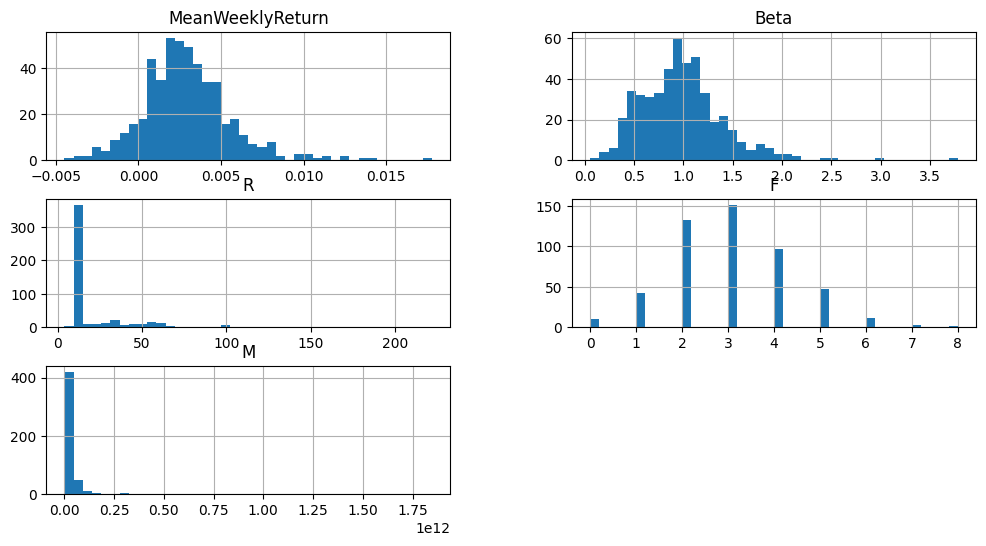


Skew after transformation:
 R    1.551618
F    0.410795
M    1.070274
dtype: float64


In [ ]:
print(common[["MeanWeeklyReturn", "Beta", "R", "F", "M"]].skew())
common[["MeanWeeklyReturn", "Beta", "R", "F", "M"]].hist(bins=40, figsize=(12, 6)); plt.show()

RR  = common[["MeanWeeklyReturn", "Beta"]].copy()
RFM = common[["R", "F", "M"]].copy()
RFM["M"] = np.log1p(RFM["M"])
RFM["R"] = np.log1p(RFM["R"])      # R skew 3.6: pulls in the 100-222 day tail
print("\nSkew after transformation:\n", RFM.skew())   # your before/after evidence
X_rr  = StandardScaler().fit_transform(RR)     # each matrix standardised separately
X_rfm = StandardScaler().fit_transform(RFM)


 Ward Risk/Return
 k  silhouette                             sizes
 2    0.350058                         [95, 400]
 3    0.284356                    [95, 188, 212]
 4    0.291131                 [6, 89, 188, 212]
 5    0.272283             [6, 89, 188, 98, 114]
 6    0.300627         [6, 89, 49, 139, 98, 114]
 7    0.296032     [6, 56, 33, 49, 139, 98, 114]
 8    0.312998 [6, 56, 33, 49, 22, 117, 98, 114]

 Ward RFM
 k  silhouette                             sizes
 2    0.396846                        [114, 381]
 3    0.326680                   [114, 138, 243]
 4    0.285717               [114, 138, 72, 171]
 5    0.303955           [114, 17, 121, 72, 171]
 6    0.289712        [18, 96, 17, 121, 72, 171]
 7    0.287752     [18, 96, 17, 57, 64, 72, 171]
 8    0.299570 [18, 35, 61, 17, 57, 64, 72, 171]

 K-means Risk/Return
 k    inertia  silhouette                            sizes
 2 631.091982    0.390274                       [349, 146]
 3 477.821222    0.318563                  [12

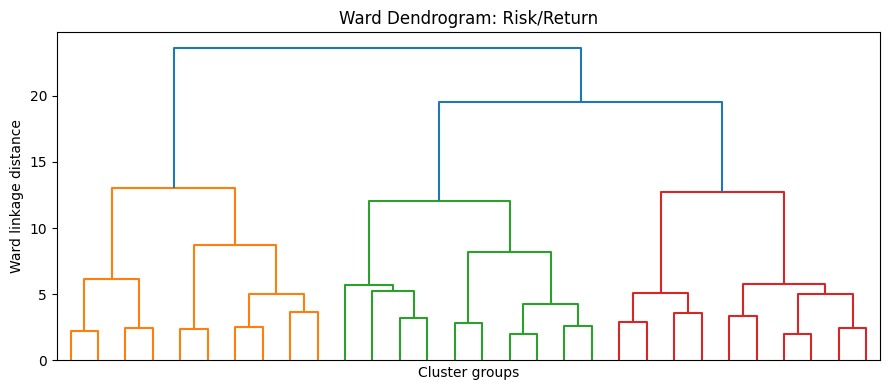

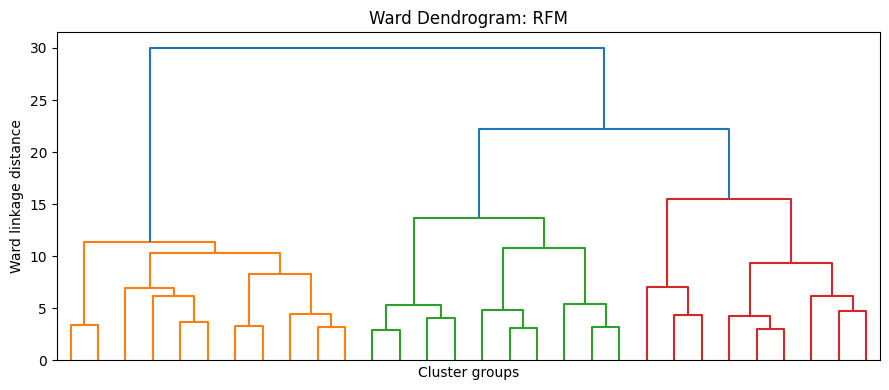

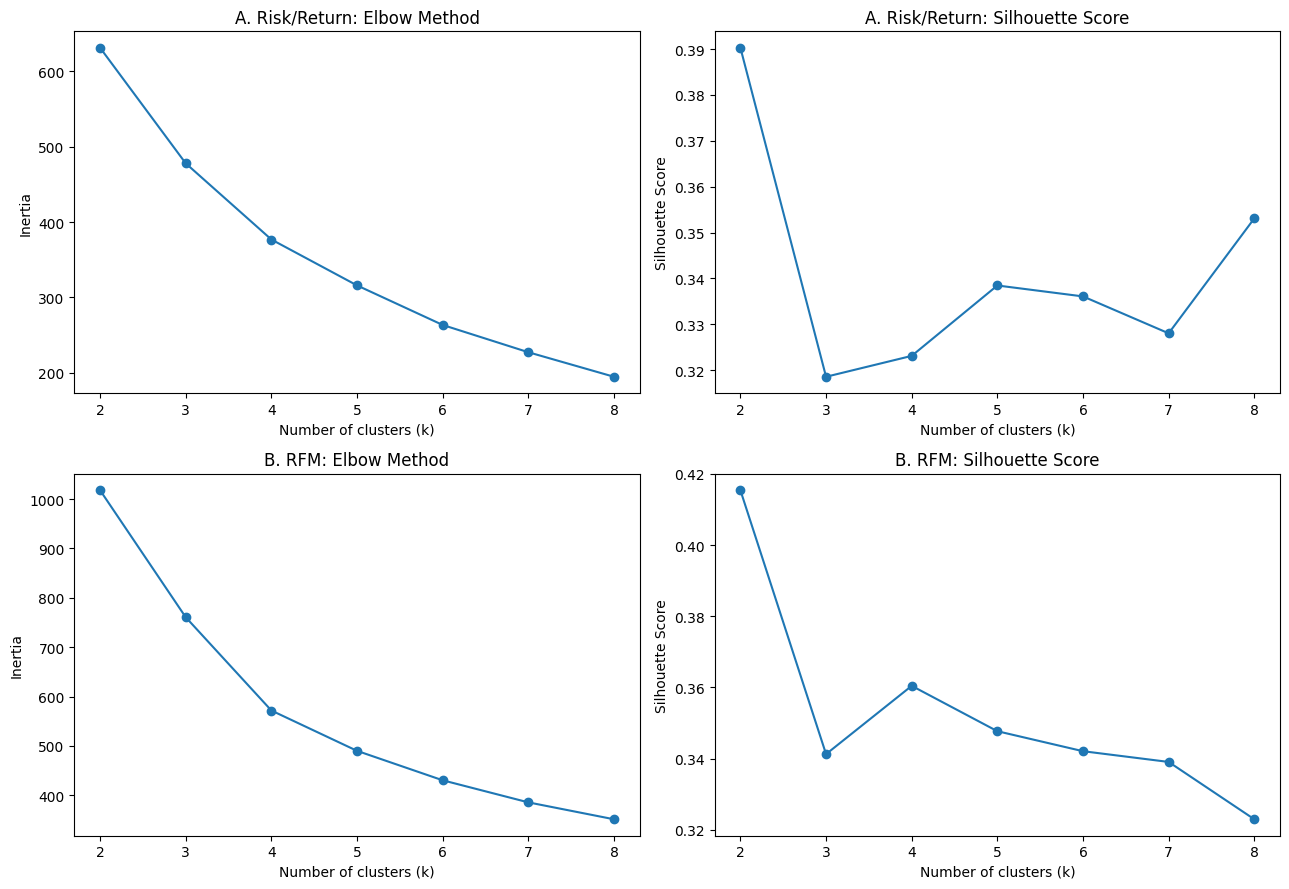

In [ ]:

# CELL 15: Clustering evaluation and visualisation

# 1. Ward hierarchical clustering evaluation
def ward_table(X):
    Z = linkage(X, method="ward")
    results = []

    for k in range(2, 9):
        labels = fcluster(Z, k, criterion="maxclust")
        number_of_clusters = len(np.unique(labels))

        if 1 < number_of_clusters < len(labels):
            score = silhouette_score(X, labels)
        else:
            score = np.nan

        results.append({
            "k": k,
            "silhouette": score,
            "sizes": np.bincount(labels)[1:].tolist()
        })

    return Z, pd.DataFrame(results)


# 2. K-means clustering evaluation
def kmeans_table(X):
    results = []

    for k in range(2, 9):
        model = KMeans(
            n_clusters=k,
            n_init=20,
            random_state=SEED
        )

        labels = model.fit_predict(X)

        results.append({
            "k": k,
            "inertia": model.inertia_,
            "silhouette": silhouette_score(X, labels),
            "sizes": np.bincount(labels).tolist()
        })

    return pd.DataFrame(results)


# 3. Run both clustering methods for both feature sets
Z_rr, w_rr = ward_table(X_rr)
Z_rfm, w_rfm = ward_table(X_rfm)

k_rr = kmeans_table(X_rr)
k_rfm = kmeans_table(X_rfm)


# 4. Display Ward clustering results
for name, table in [
    ("Ward Risk/Return", w_rr),
    ("Ward RFM", w_rfm)
]:
    print("\n", name)
    print(table.to_string(index=False))


# 5. Display K-means clustering results
for name, table in [
    ("K-means Risk/Return", k_rr),
    ("K-means RFM", k_rfm)
]:
    print("\n", name)
    print(table.to_string(index=False))


# 6. Ward hierarchical dendrograms
for Z, name in [
    (Z_rr, "Risk/Return"),
    (Z_rfm, "RFM")
]:
    plt.figure(figsize=(9, 4))

    dendrogram(
        Z,
        truncate_mode="lastp",
        p=30,
        no_labels=True
    )

    plt.title(f"Ward Dendrogram: {name}")
    plt.xlabel("Cluster groups")
    plt.ylabel("Ward linkage distance")
    plt.tight_layout()
    plt.show()


# 7. Plot all four K-means evaluation graphs
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# Graph 1: Risk/Return Elbow
ax[0, 0].plot(
    k_rr["k"],
    k_rr["inertia"],
    marker="o"
)
ax[0, 0].set_title("A. Risk/Return: Elbow Method")
ax[0, 0].set_xlabel("Number of clusters (k)")
ax[0, 0].set_ylabel("Inertia")
ax[0, 0].set_xticks(k_rr["k"])


# Graph 2: Risk/Return Silhouette
ax[0, 1].plot(
    k_rr["k"],
    k_rr["silhouette"],
    marker="o"
)
ax[0, 1].set_title("A. Risk/Return: Silhouette Score")
ax[0, 1].set_xlabel("Number of clusters (k)")
ax[0, 1].set_ylabel("Silhouette Score")
ax[0, 1].set_xticks(k_rr["k"])


# Graph 3: RFM Elbow
ax[1, 0].plot(
    k_rfm["k"],
    k_rfm["inertia"],
    marker="o"
)
ax[1, 0].set_title("B. RFM: Elbow Method")
ax[1, 0].set_xlabel("Number of clusters (k)")
ax[1, 0].set_ylabel("Inertia")
ax[1, 0].set_xticks(k_rfm["k"])


# Graph 4: RFM Silhouette
ax[1, 1].plot(
    k_rfm["k"],
    k_rfm["silhouette"],
    marker="o"
)
ax[1, 1].set_title("B. RFM: Silhouette Score")
ax[1, 1].set_xlabel("Number of clusters (k)")
ax[1, 1].set_ylabel("Silhouette Score")
ax[1, 1].set_xticks(k_rfm["k"])


plt.tight_layout()
plt.show()


In [ ]:
# Choose k transparently from the evaluated range (2–8) using the highest
# silhouette score for each method/feature set. Review the elbow charts and
# cluster sizes below as well; silhouette is evidence, not the only business decision.
def best_k_from_silhouette(table):
    best_row = table.loc[table["silhouette"].idxmax()]
    return int(best_row["k"]), float(best_row["silhouette"])

k_ward_rr, sil_ward_rr = best_k_from_silhouette(w_rr)
k_ward_rfm, sil_ward_rfm = best_k_from_silhouette(w_rfm)
k_km_rr, sil_km_rr = best_k_from_silhouette(k_rr)
k_km_rfm, sil_km_rfm = best_k_from_silhouette(k_rfm)

K = {
    "ward_rr": k_ward_rr,
    "ward_rfm": k_ward_rfm,
    "km_rr": k_km_rr,
    "km_rfm": k_km_rfm
}
print("Selected cluster counts (highest silhouette over k=2..8):")

Selected cluster counts (highest silhouette over k=2..8):


In [ ]:
# Create cluster assignments
common["ward_rr"] = fcluster(
    Z_rr, K["ward_rr"], criterion="maxclust"
)

common["ward_rfm"] = fcluster(
    Z_rfm, K["ward_rfm"], criterion="maxclust"
)

common["km_rr"] = KMeans(
    n_clusters=K["km_rr"],
    n_init=20,
    random_state=SEED
).fit_predict(X_rr)

common["km_rfm"] = KMeans(
    n_clusters=K["km_rfm"],
    n_init=20,
    random_state=SEED
).fit_predict(X_rfm)

print("Cluster assignments created successfully.")

Cluster assignments created successfully.



== ward_rr
        MeanWeeklyReturn            Beta      
                    mean count      mean count
ward_rr                                       
1               0.006477    95  1.325879    95
2               0.002082   400  0.900553   400

== km_rr
      MeanWeeklyReturn            Beta      
                  mean count      mean count
km_rr                                       
0             0.001867   349  0.818072   349
1             0.005456   146  1.374470   146

== ward_rfm
                  R        F             M
ward_rfm                                  
1         51.114035  2.45614  4.537515e+10
2         11.375328  3.16273  3.791672e+10

== km_rfm
                R         F             M
km_rfm                                   
0       11.654731  3.181586  3.261206e+10
1       53.884615  2.317308  6.603578e+10


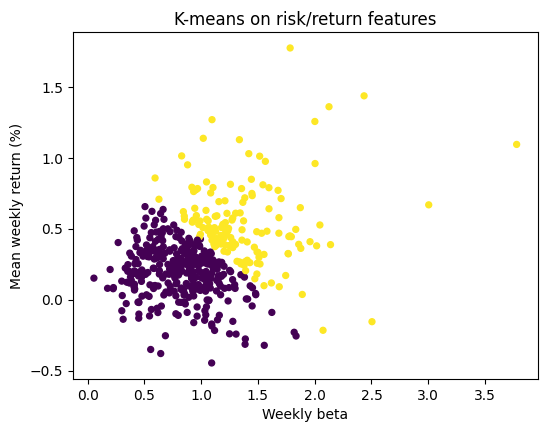

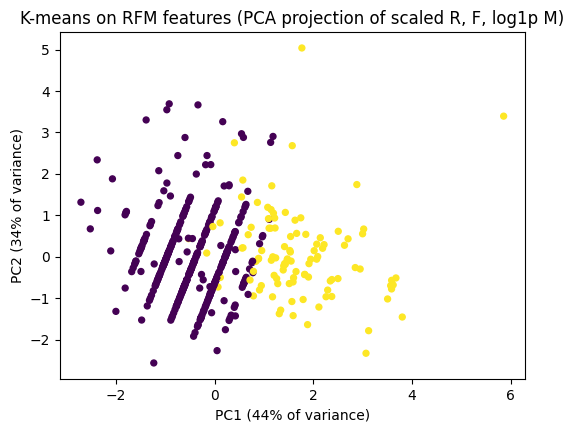

K-means RFM    0    1
Ward RFM             
1             12  102
2            379    2
ARI Ward vs K-means (RFM): 0.878
ARI Ward vs K-means (risk/return): 0.605


In [ ]:
for col in ["ward_rr", "km_rr"]:
    print("\n==", col); print(common.groupby(col)[["MeanWeeklyReturn", "Beta"]].agg(["mean", "count"]))
for col in ["ward_rfm", "km_rfm"]:
    print("\n==", col); print(common.groupby(col)[["R", "F", "M"]].mean())   # M in USD

plt.figure(figsize=(6, 4.5))
plt.scatter(common["Beta"], common["MeanWeeklyReturn"] * 100, c=common["km_rr"], cmap="viridis", s=18)
plt.xlabel("Weekly beta"); plt.ylabel("Mean weekly return (%)"); plt.title("K-means on risk/return features"); plt.show()

pca = PCA(2, random_state=SEED); P = pca.fit_transform(X_rfm)
plt.figure(figsize=(6, 4.5))
plt.scatter(P[:, 0], P[:, 1], c=common["km_rfm"], cmap="viridis", s=18)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
plt.title("K-means on RFM features (PCA projection of scaled R, F, log1p M)"); plt.show()

print(pd.crosstab(common["ward_rfm"], common["km_rfm"], rownames=["Ward RFM"], colnames=["K-means RFM"]))
print("ARI Ward vs K-means (RFM):", round(adjusted_rand_score(common["ward_rfm"], common["km_rfm"]), 3))
print("ARI Ward vs K-means (risk/return):", round(adjusted_rand_score(common["ward_rr"], common["km_rr"]), 3))

       R      F      M
R  1.000 -0.279  0.144
F -0.279  1.000  0.019
M  0.144  0.019  1.000
ARI (full Ward RFM vs R,F only): 0.817

Median traded value M (USD) by full-model cluster:
 ward_rfm
1    2.095020e+10
2    1.531712e+10
Name: M, dtype: float64

Median traded value M (USD) by R,F-only cluster:
 ward_rf_only
1    2.105259e+10
2    1.539575e+10
Name: M, dtype: float64


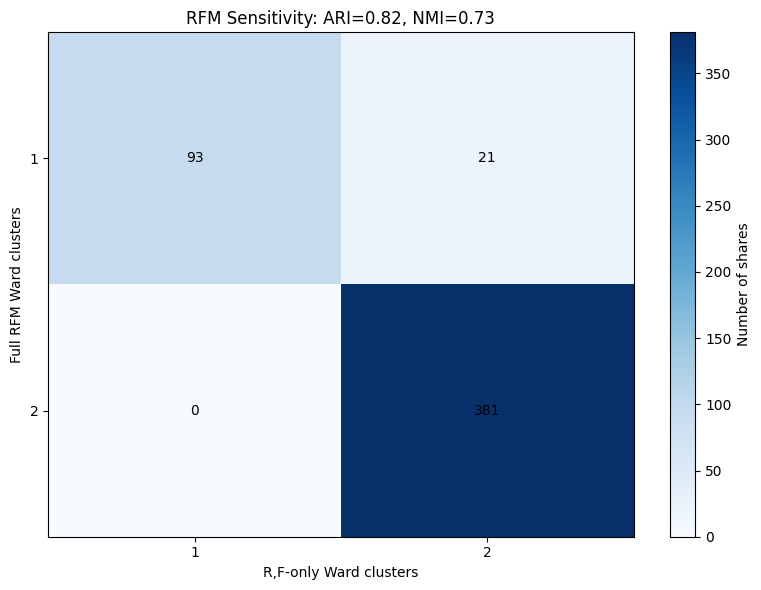

Sensitivity ARI: 0.817
Sensitivity NMI: 0.73


In [ ]:
from sklearn.metrics import normalized_mutual_info_score

print(RFM.corr().round(3))

X_rf   = StandardScaler().fit_transform(common[["R", "F"]])               # standardised afresh
lab_rf = fcluster(linkage(X_rf, method="ward"), K["ward_rfm"], "maxclust")  # same shares, same k
common["ward_rf_only"] = lab_rf
sensitivity_overlap = pd.crosstab(
    common["ward_rfm"],
    common["ward_rf_only"]
)
print("ARI (full Ward RFM vs R,F only):", round(adjusted_rand_score(common["ward_rfm"], lab_rf), 3))
sensitivity_overlap = pd.crosstab(
    common["ward_rfm"],
    common["ward_rf_only"]
)
print("\nMedian traded value M (USD) by full-model cluster:\n", common.groupby("ward_rfm")["M"].median())
print("\nMedian traded value M (USD) by R,F-only cluster:\n", common.groupby("ward_rf_only")["M"].median())
common.to_csv("feature_table_with_clusters.csv")
# RFM sensitivity: Full RFM vs R,F-only
pd.crosstab(
    common["ward_rfm"],
    common["ward_rf_only"]
)

sensitivity_ari = adjusted_rand_score(
    common["ward_rfm"],
    common["ward_rf_only"]
)

sensitivity_nmi = normalized_mutual_info_score(
    common["ward_rfm"],
    common["ward_rf_only"]
)

plt.figure(figsize=(8, 6))

plt.imshow(sensitivity_overlap.values, cmap="Blues", aspect="auto")

plt.colorbar(label="Number of shares")

plt.xticks(
    range(len(sensitivity_overlap.columns)),
    sensitivity_overlap.columns
)

plt.yticks(
    range(len(sensitivity_overlap.index)),
    sensitivity_overlap.index
)

plt.xlabel("R,F-only Ward clusters")
plt.ylabel("Full RFM Ward clusters")

plt.title(
    f"RFM Sensitivity: ARI={sensitivity_ari:.2f}, "
    f"NMI={sensitivity_nmi:.2f}"
)

for i in range(sensitivity_overlap.shape[0]):
    for j in range(sensitivity_overlap.shape[1]):

        plt.text(
            j, i,
            str(sensitivity_overlap.iloc[i, j]),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.savefig(
    "rfm_sensitivity_overlap_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Sensitivity ARI:", round(sensitivity_ari, 3))
print("Sensitivity NMI:", round(sensitivity_nmi, 3))

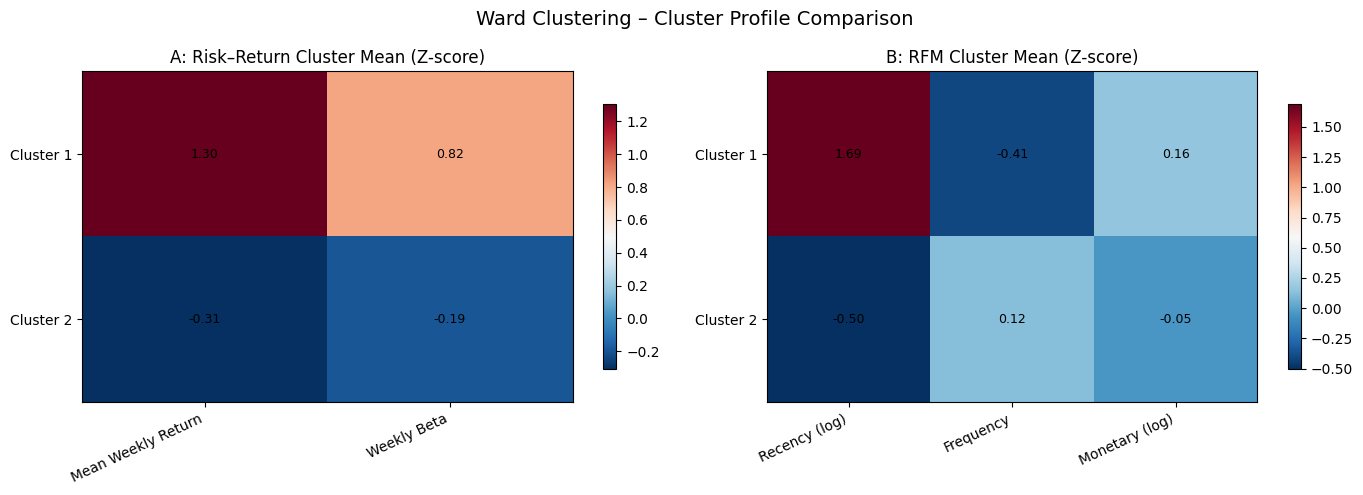

Risk–Return Cluster Profiles:


,Mean Weekly Return,Weekly Beta
ward_rr,,
1,1.304,0.817
2,-0.310,-0.194


RFM Cluster Profiles:


,Recency (log),Frequency,Monetary (log)
ward_rfm,,,
1,1.687,-0.410,0.160
2,-0.505,0.123,-0.048


In [ ]:

# Task 2.4 – Cluster Profile Heatmaps
# Compare average standardised feature values across Ward clusters.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create dataframes using the already-standardised feature matrices.
rr_scaled = pd.DataFrame(
    X_rr,
    index=common.index,
    columns=["Mean Weekly Return", "Weekly Beta"]
)

rfm_scaled = pd.DataFrame(
    X_rfm,
    index=common.index,
    columns=["Recency (log)", "Frequency", "Monetary (log)"]
)

# Calculate mean feature values for each Ward cluster.
rr_profile = rr_scaled.groupby(common["ward_rr"]).mean()
rfm_profile = rfm_scaled.groupby(common["ward_rfm"]).mean()

# Plot both cluster profile heatmaps.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

heatmaps = [
    (rr_profile, "A: Risk–Return Cluster Mean (Z-score)", axes[0]),
    (rfm_profile, "B: RFM Cluster Mean (Z-score)", axes[1])
]

for profile, title, ax in heatmaps:
    values = profile.values
    im = ax.imshow(values, cmap="RdBu_r", aspect="auto")

    ax.set_title(title)
    ax.set_yticks(range(len(profile.index)))
    ax.set_yticklabels([f"Cluster {i}" for i in profile.index])
    ax.set_xticks(range(len(profile.columns)))
    ax.set_xticklabels(profile.columns, rotation=25, ha="right")

    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}",
                    ha="center", va="center", fontsize=9)

    fig.colorbar(im, ax=ax, shrink=0.8)

plt.suptitle("Ward Clustering – Cluster Profile Comparison", fontsize=14)
plt.tight_layout()
plt.savefig("cluster_profile_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

print("Risk–Return Cluster Profiles:")
display(rr_profile.round(3))

print("RFM Cluster Profiles:")
display(rfm_profile.round(3))



Ward Risk/Return vs Ward RFM:
Ward RFM           1    2
Ward Risk/Return         
1                 28   67
2                 86  314
ARI Risk/Return vs RFM (Ward): 0.039


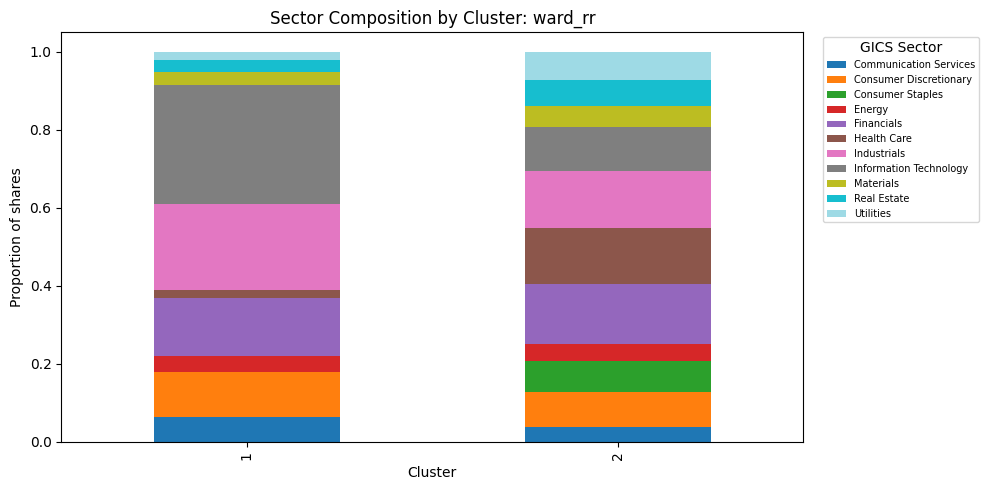

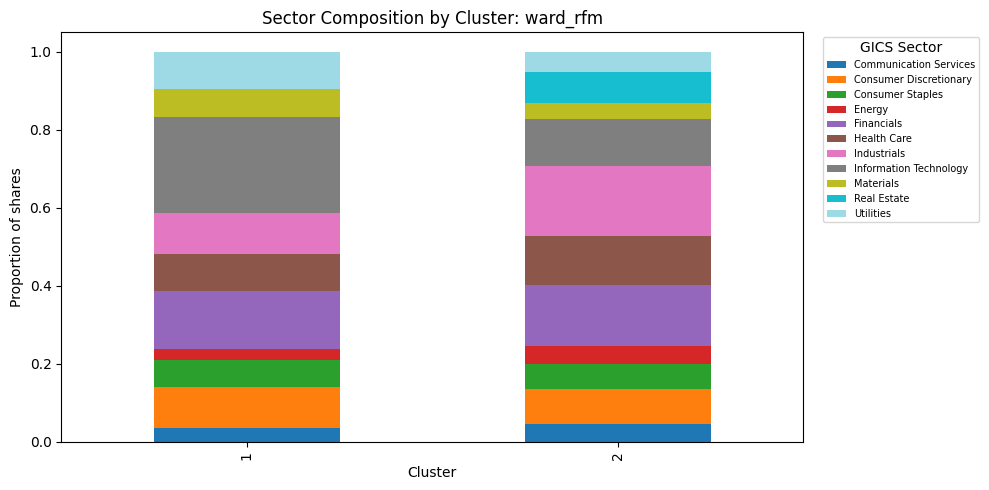

In [ ]:

# Compare Ward Risk/Return and Ward RFM clusters

# 1. Compare cluster assignments
print("Ward Risk/Return vs Ward RFM:")
print(
    pd.crosstab(
        common["ward_rr"],
        common["ward_rfm"],
        rownames=["Ward Risk/Return"],
        colnames=["Ward RFM"]
    )
)

# 2. Calculate Adjusted Rand Index
ari = adjusted_rand_score(
    common["ward_rr"],
    common["ward_rfm"]
)

print("ARI Risk/Return vs RFM (Ward):", round(ari, 3))


# 3. Sector composition by cluster
for col in ["ward_rr", "ward_rfm"]:

    comp = pd.crosstab(
        common[col],
        common["GICS_Sector"],
        normalize="index"
    )

    comp.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5),
        colormap="tab20"
    )

    plt.xlabel("Cluster")
    plt.ylabel("Proportion of shares")
    plt.title(f"Sector Composition by Cluster: {col}")
    plt.legend(
        title="GICS Sector",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=7
    )

    plt.tight_layout()
    plt.show()


In [ ]:

import os
import zipfile
from google.colab import files

files_to_download = [
    "feature_table_with_clusters.csv",
    "inclusion_exclusion_log.csv",
    "sp500_constituents.csv",
    "weekly_features.csv",
    "rfm_features.csv",
    "run_metadata.json"
]

zip_name = "SP500_Coursework_Files.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for filename in files_to_download:
        if os.path.exists(filename):
            zipf.write(filename)
            print("Added:", filename)
        else:
            print("Not found:", filename)

files.download(zip_name)


Added: feature_table_with_clusters.csv
Added: inclusion_exclusion_log.csv
Added: sp500_constituents.csv
Not found: weekly_features.csv
Not found: rfm_features.csv
Not found: run_metadata.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Simple star-schema data mart export.
# Fact table grain: one row per ticker for this single observation date.
fact_stock_features = common.reset_index().rename(columns={"index": "Ticker"}).copy()
fact_stock_features["ObservationDate"] = OBS_DATE.date().isoformat()
fact_stock_features.to_csv("fact_stock_features.csv", index=False)

dim_stock = constituents[["Ticker", "Security", "GICS Sector", "GICS Sub-Industry"]].copy()
dim_stock = dim_stock.drop_duplicates("Ticker")
dim_stock.to_csv("dim_stock.csv", index=False)

dim_date = pd.DataFrame([{
    "ObservationDate": OBS_DATE.date().isoformat(),
    "Year": OBS_DATE.year,
    "Month": OBS_DATE.month,
    "Quarter": OBS_DATE.quarter,
    "Weekday": OBS_DATE.day_name()
}])
dim_date.to_csv("dim_observation_date.csv", index=False)

print("Data mart exports created: fact_stock_features.csv, dim_stock.csv, dim_observation_date.csv")


Data mart exports created: fact_stock_features.csv, dim_stock.csv, dim_observation_date.csv


In [ ]:
# Save reproducible data snapshots and final outputs.
# These files should be included in your public coursework repository (subject to file-size limits).
for filename, frame in [
    ("weekly_features.csv", wk),
    ("rfm_features.csv", rfm),
    ("final_feature_table_with_clusters.csv", common),
    ("inclusion_exclusion_log.csv", inclusion_exclusion_log),
    ("daily_data_quality_report.csv", missing_report),
    ("corporate_action_audit.csv", split_audit),
    ("corporate_action_flags.csv", corporate_flags)
]:
    frame.to_csv(filename)

# Snapshot metadata: period, source, retrieval/run date, observation date and package versions.
metadata = {
    "data_source": "Yahoo Finance via yfinance; S&P 500 constituent list from Wikipedia",
    "benchmark": BENCHMARK,
    "start_date_inclusive": START,
    "end_date_exclusive": END,
    "ticker_list_retrieval_date": RETRIEVAL_DATE,
    "run_date": dt.date.today().isoformat(),
    "observation_date": OBS_DATE.date().isoformat(),
    "last_complete_week": LAST_FULL_WEEK.date().isoformat(),
    "minimum_aligned_weekly_returns": MIN_WEEKS,
    "minimum_daily_sessions_for_RFM": MIN_SESSIONS,
    "common_valid_share_count": int(len(common)),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "yfinance": yf.__version__,
    "scikit_learn": sklearn.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__
}
with open("run_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)
print(json.dumps(metadata, indent=2))


{
  "data_source": "Yahoo Finance via yfinance; S&P 500 constituent list from Wikipedia",
  "benchmark": "^GSPC",
  "start_date_inclusive": "2021-01-01",
  "end_date_exclusive": "2025-01-01",
  "ticker_list_retrieval_date": "2026-11-23",
  "run_date": "2026-11-23",
  "observation_date": "2024-12-31",
  "last_complete_week": "2024-12-27",
  "minimum_aligned_weekly_returns": 52,
  "minimum_daily_sessions_for_RFM": 80,
  "common_valid_share_count": 495,
  "pandas": "2.2.3",
  "numpy": "2.4.6",
  "yfinance": "0.2.66",
  "scikit_learn": "1.6.1",
  "scipy": "1.16.3",
  "matplotlib": "3.10.0"
}
